In [2]:
# Imports
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LightSource
import laspy
import rasterio
from rasterio.plot import show
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

# Try to import Open3D for 3D visualization (optional)
try:
    import open3d as o3d
    HAS_OPEN3D = True
    print("✅ Open3D available for 3D visualization")
except ImportError:
    HAS_OPEN3D = False
    print("⚠️ Open3D not available (install with: pip install open3d)")

print("✅ Imports successful")

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.
✅ Open3D available for 3D visualization
✅ Imports successful


## Configuration

Set paths to your LAS point cloud and DSM files.

In [3]:
# === SITE 1: DD0001 ===
# LiDAR L1
# las_path = "/media/laura/laura_usb/uas_data/DD0001/lidar/20220519_SASMDD0001_triple_AusGeoid.las"
# dsm_path = "/media/laura/laura_usb/uas_data/DD0001/lidar/dsm/SASMDD0001_l1_dsm_03.tif"

# LiDAR L2
# las_path = "/media/laura/laura_usb/uas_data/DD0001/lidar_l2/cloud2d765c57b8471e2c.las"
# dsm_path = "/media/laura/laura_usb/uas_data/DD0001/lidar_l2/dsm/SASMDD0001_l2_dsm_03.tif"

# Riegl VUX-120
# las_path = "/media/laura/laura_usb/uas_data/DD0001/riegl_vux120/SASMDD0001_riegl_80_crosshatch.laz"
# dsm_path = "/media/laura/laura_usb/uas_data/DD0001/riegl_vux120/dsm/SASMDD0001_riegl_dsm_03.tif"

# === SITE 11: DD0011 ===
# LiDAR L1
# las_path = "/data/calperumResearch/site2_1_DD0011/lidar/20220517_SASMDD0011_AusGeoid20.las"
# dsm_path = "/data/calperumResearch/site2_1_DD0011/lidar/dsm/SASMDD0011_l1_dsm_03.tif"

# LiDAR L2
las_path = "/data/calperumResearch/site2_1_DD0011/lidar_l2/cloud3358f88f2d9dc868.las"
dsm_path = "/data/calperumResearch/site2_1_DD0011/lidar_l2/dsm/SASMDD0011_l2_dsm_03.tif"

print("="*70)
print("CONFIGURATION")
print("="*70)
print(f"LAS file: {las_path}")
print(f"DSM file: {dsm_path}")
print("="*70)

CONFIGURATION
LAS file: /data/calperumResearch/site2_1_DD0011/lidar_l2/cloud3358f88f2d9dc868.las
DSM file: /data/calperumResearch/site2_1_DD0011/lidar_l2/dsm/SASMDD0011_l2_dsm_03.tif


## Inspect LAS Point Cloud

In [4]:
# Load LAS file
if Path(las_path).exists():
    print(f"✅ Loading LAS file: {Path(las_path).name}\n")
    las = laspy.read(las_path)
    
    # Basic info
    print("--- LAS FILE METADATA ---")
    print(f"LAS Version: {las.header.version}")
    print(f"Point Format: {las.header.point_format.id}")
    print(f"Total Points: {las.header.point_count:,}")
    
    # Coordinate ranges
    print(f"\n--- COORDINATE RANGES ---")
    print(f"X: {las.header.x_min:.3f} to {las.header.x_max:.3f} ({las.header.x_max - las.header.x_min:.3f} m)")
    print(f"Y: {las.header.y_min:.3f} to {las.header.y_max:.3f} ({las.header.y_max - las.header.y_min:.3f} m)")
    print(f"Z: {las.header.z_min:.3f} to {las.header.z_max:.3f} ({las.header.z_max - las.header.z_min:.3f} m)")
    
    # Available dimensions
    print(f"\n--- AVAILABLE DIMENSIONS ---")
    print(f"{', '.join(las.point_format.dimension_names)}")
    
    # Classification info (if available)
    if 'classification' in las.point_format.dimension_names:
        unique_classes = np.unique(las.classification)
        print(f"\n--- CLASSIFICATION ---")
        for cls in unique_classes:
            count = np.sum(las.classification == cls)
            pct = 100 * count / len(las.classification)
            print(f"  Class {cls}: {count:,} points ({pct:.2f}%)")
    
    # Extract coordinates for visualization
    x = las.x
    y = las.y
    z = las.z
    
    print(f"\n✅ Point cloud loaded successfully")
else:
    print(f"❌ LAS file not found: {las_path}")

✅ Loading LAS file: cloud3358f88f2d9dc868.las

--- LAS FILE METADATA ---
LAS Version: 1.2
Point Format: 3
Total Points: 69,596,825

--- COORDINATE RANGES ---
X: 473141.522 to 473329.766 (188.244 m)
Y: 6235618.928 to 6235907.064 (288.136 m)
Z: 26.837 to 39.498 (12.660 m)

--- AVAILABLE DIMENSIONS ---
X, Y, Z, intensity, return_number, number_of_returns, scan_direction_flag, edge_of_flight_line, classification, synthetic, key_point, withheld, scan_angle_rank, user_data, point_source_id, gps_time, red, green, blue

--- CLASSIFICATION ---
  Class 1: 4,759,204 points (6.84%)
  Class 2: 64,837,621 points (93.16%)

✅ Point cloud loaded successfully


## Visualize Point Cloud - 2D Views

Subsampling 69,596,825 points → 500,697 points for visualization


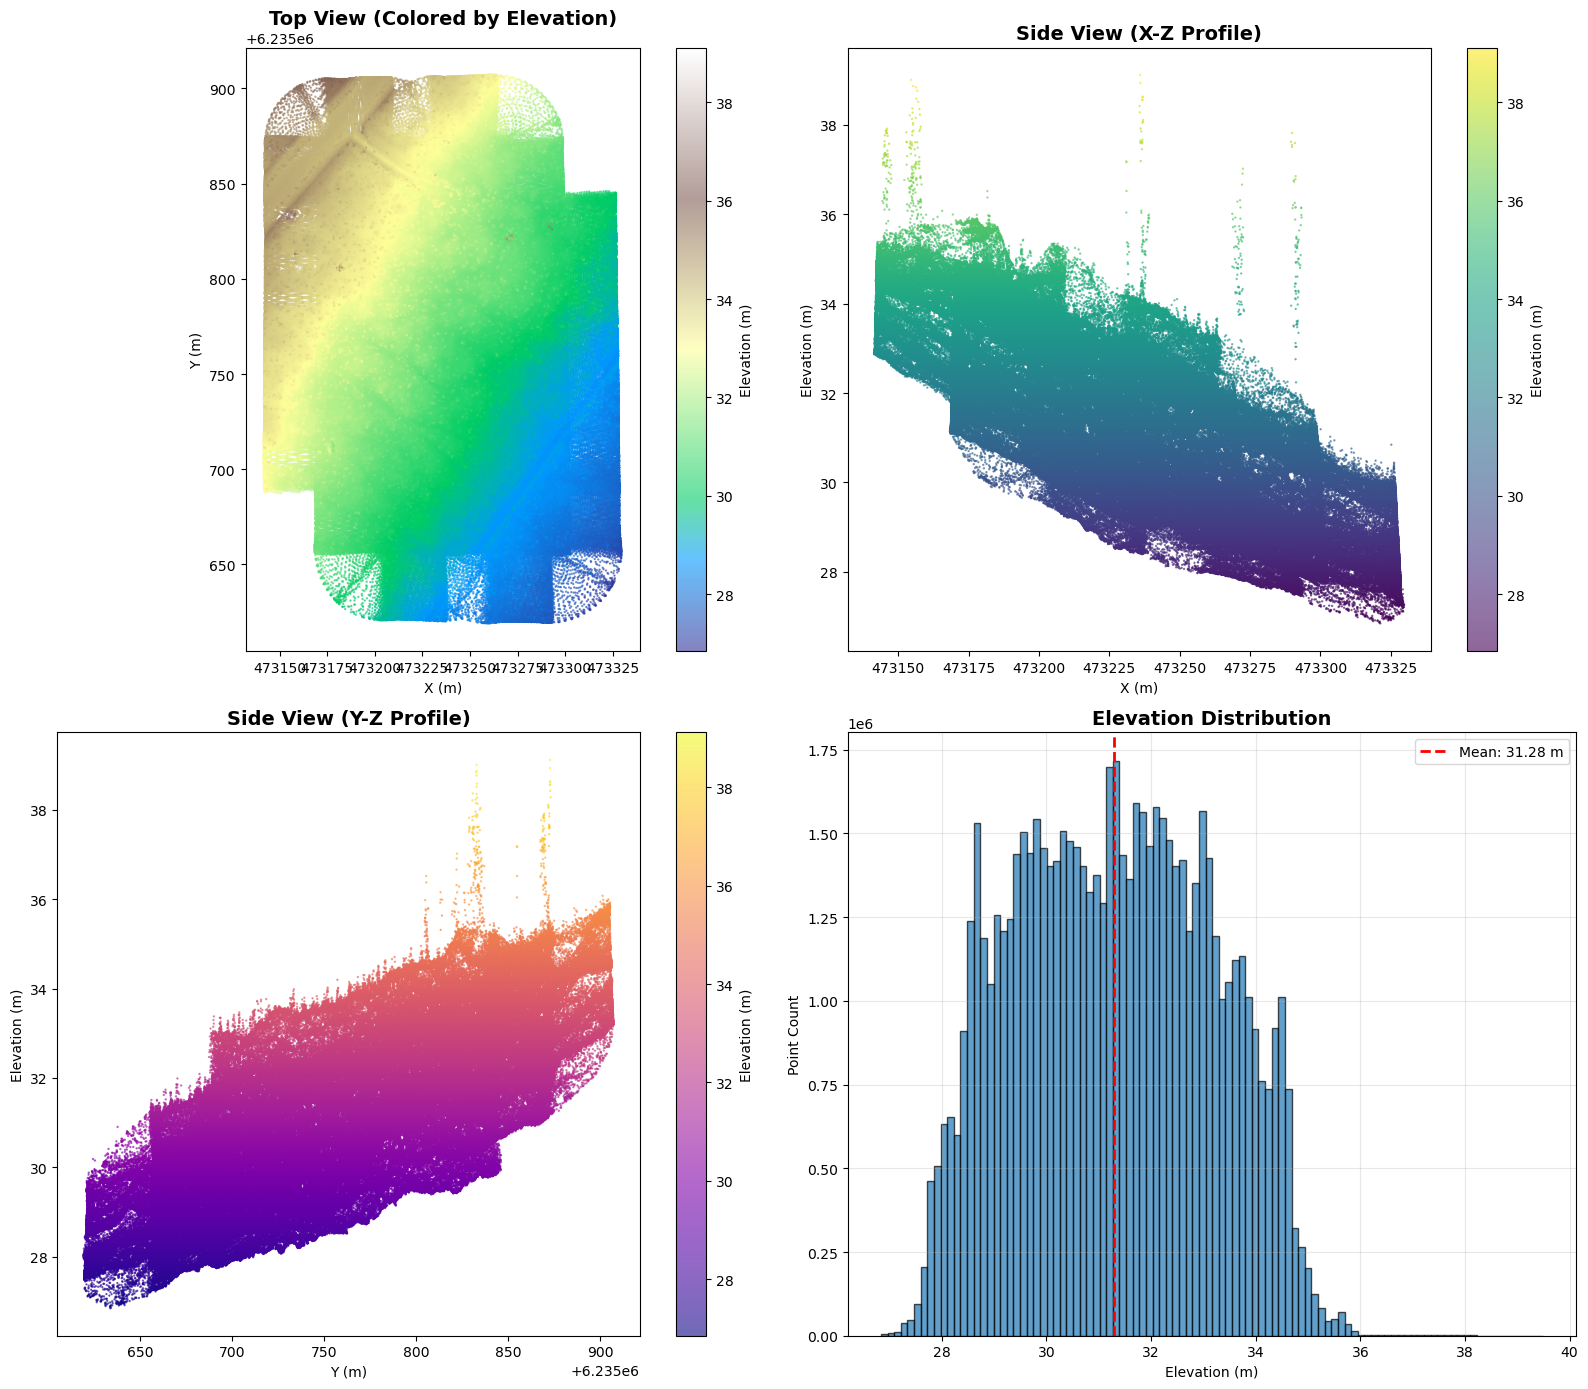


📊 Elevation Statistics:
  Mean:  31.284 m
  Std:   1.869 m
  Min:   26.837 m
  Max:   39.498 m
  Range: 12.660 m


In [11]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import laspy

# 2D visualization of point cloud
if Path(las_path).exists():

    # Read LAS and convert laspy ScaledArrayView -> NumPy arrays (scaled units, metres)
    las = laspy.read(las_path)
    x = np.array(las.x, dtype=np.float64)
    y = np.array(las.y, dtype=np.float64)
    z = np.array(las.z, dtype=np.float64)

    max_points = 500000
    if z.size > max_points:
        step = max(1, z.size // max_points)
        x_sub = x[::step]
        y_sub = y[::step]
        z_sub = z[::step]
        print(f"Subsampling {z.size:,} points → {z_sub.size:,} points for visualization")
    else:
        x_sub, y_sub, z_sub = x, y, z

    fig, axes = plt.subplots(2, 2, figsize=(16, 14))

    # Top view
    sc1 = axes[0, 0].scatter(x_sub, y_sub, c=z_sub, s=0.5, cmap="terrain", alpha=0.6)
    axes[0, 0].set_title("Top View (Colored by Elevation)", fontsize=14, fontweight="bold")
    axes[0, 0].set_xlabel("X (m)")
    axes[0, 0].set_ylabel("Y (m)")
    axes[0, 0].set_aspect("equal")
    plt.colorbar(sc1, ax=axes[0, 0], label="Elevation (m)")

    # Side X-Z
    sc2 = axes[0, 1].scatter(x_sub, z_sub, c=z_sub, s=0.5, cmap="viridis", alpha=0.6)
    axes[0, 1].set_title("Side View (X-Z Profile)", fontsize=14, fontweight="bold")
    axes[0, 1].set_xlabel("X (m)")
    axes[0, 1].set_ylabel("Elevation (m)")
    plt.colorbar(sc2, ax=axes[0, 1], label="Elevation (m)")

    # Side Y-Z
    sc3 = axes[1, 0].scatter(y_sub, z_sub, c=z_sub, s=0.5, cmap="plasma", alpha=0.6)
    axes[1, 0].set_title("Side View (Y-Z Profile)", fontsize=14, fontweight="bold")
    axes[1, 0].set_xlabel("Y (m)")
    axes[1, 0].set_ylabel("Elevation (m)")
    plt.colorbar(sc3, ax=axes[1, 0], label="Elevation (m)")

    # Histogram + stats
    z_mean = float(np.mean(z))
    axes[1, 1].hist(z, bins=100, edgecolor="black", alpha=0.7)
    axes[1, 1].set_title("Elevation Distribution", fontsize=14, fontweight="bold")
    axes[1, 1].set_xlabel("Elevation (m)")
    axes[1, 1].set_ylabel("Point Count")
    axes[1, 1].axvline(z_mean, color="red", linestyle="--", linewidth=2, label=f"Mean: {z_mean:.2f} m")
    axes[1, 1].legend()
    axes[1, 1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

    print("\n📊 Elevation Statistics:")
    print(f"  Mean:  {np.mean(z):.3f} m")
    print(f"  Std:   {np.std(z):.3f} m")
    print(f"  Min:   {np.min(z):.3f} m")
    print(f"  Max:   {np.max(z):.3f} m")
    print(f"  Range: {(np.max(z) - np.min(z)):.3f} m")

else:
    print("LAS file does not exist:", las_path)


## Visualize Point Cloud - 3D Interactive

**Note:** Open3D requires X11 display. On SSH, this cell will save a screenshot instead of showing interactive view.

In [ ]:
# 3D visualization with Open3D (if available)
if HAS_OPEN3D and Path(las_path).exists():
    print("Creating 3D point cloud visualization...")
    
    # Convert to numpy arrays
    x_arr = np.array(x)
    y_arr = np.array(y)
    z_arr = np.array(z)
    
    # Subsample for performance
    max_points_3d = 200000
    if len(x_arr) > max_points_3d:
        step = len(x_arr) // max_points_3d
        points_3d = np.column_stack([x_arr[::step], y_arr[::step], z_arr[::step]])
    else:
        points_3d = np.column_stack([x_arr, y_arr, z_arr])
    
    # Create Open3D point cloud
    pcd = o3d.geometry.PointCloud()
    pcd.points = o3d.utility.Vector3dVector(points_3d)
    
    # Color by elevation
    z_normalized = (points_3d[:, 2] - points_3d[:, 2].min()) / (points_3d[:, 2].max() - points_3d[:, 2].min())
    colors = plt.cm.terrain(z_normalized)[:, :3]  # RGB only
    pcd.colors = o3d.utility.Vector3dVector(colors)
    
    print(f"Point cloud: {len(pcd.points):,} points")
    
    # Try interactive visualization first, fall back to screenshot if fails
    try:
        print("\n⚠️ Attempting interactive 3D view (will timeout after 3 seconds if no display)...")
        o3d.visualization.draw_geometries([pcd], 
                                          window_name="LiDAR Point Cloud",
                                          width=1200, 
                                          height=800,
                                          point_show_normal=False)
        print("✅ Interactive view displayed successfully")
        
    except Exception as e:
        print(f"\n⚠️ Cannot display interactive view: {e}")
        print("   Saving screenshots instead (SSH mode)...\n")
        
        # Use offscreen rendering to save screenshots
        vis = o3d.visualization.Visualizer()
        vis.create_window(window_name="Point Cloud", width=1200, height=800, visible=False)
        vis.add_geometry(pcd)
        
        # Set view control parameters
        view_control = vis.get_view_control()
        
        # Output directory for screenshots
        output_dir = Path(las_path).parent / "visualizations"
        output_dir.mkdir(exist_ok=True)
        
        # Capture multiple views
        views = {
            'top': {'front': [0, 0, 1], 'lookat': points_3d.mean(axis=0), 'up': [0, 1, 0], 'zoom': 0.7},
            'side_x': {'front': [1, 0, 0], 'lookat': points_3d.mean(axis=0), 'up': [0, 0, 1], 'zoom': 0.7},
            'side_y': {'front': [0, 1, 0], 'lookat': points_3d.mean(axis=0), 'up': [0, 0, 1], 'zoom': 0.7},
            'oblique': {'front': [1, 1, 1], 'lookat': points_3d.mean(axis=0), 'up': [0, 0, 1], 'zoom': 0.5}
        }
        
        for view_name, view_params in views.items():
            # Reset view
            vis.reset_view_point(True)
            
            # Set camera parameters
            ctr = vis.get_view_control()
            ctr.set_front(view_params['front'])
            ctr.set_lookat(view_params['lookat'])
            ctr.set_up(view_params['up'])
            ctr.set_zoom(view_params['zoom'])
            
            # Update rendering
            vis.poll_events()
            vis.update_renderer()
            
            # Save screenshot
            screenshot_path = output_dir / f"{Path(las_path).stem}_3d_{view_name}.png"
            vis.capture_screen_image(str(screenshot_path), do_render=True)
            print(f"   ✅ Saved: {screenshot_path}")
        
        vis.destroy_window()
        print(f"\n✅ All screenshots saved to: {output_dir}")
        
elif not HAS_OPEN3D:
    print("⚠️ Open3D not available. Install with: pip install open3d")
else:
    print("❌ LAS file not loaded")

Creating 3D point cloud visualization...
Point cloud: 200,568 points

⚠️ If running over SSH, visualization window may not display.
   The window will attempt to open for 5 seconds...

[Open3D WARNING] GLFW Error: Failed to detect any supported platform
[Open3D WARNING] GLFW initialized for headless rendering.
[Open3D WARNING] GLFW Error: OSMesa: Library not found
[Open3D WARNING] Failed to create window
[Open3D WARNING] [DrawGeometries] Failed creating OpenGL window.


## Inspect DSM Raster

In [6]:
# Load DSM raster
if Path(dsm_path).exists():
    print(f"✅ Loading DSM: {Path(dsm_path).name}\n")
    
    with rasterio.open(dsm_path) as src:
        dsm = src.read(1)
        dsm_profile = src.profile
        dsm_bounds = src.bounds
        dsm_transform = src.transform
        nodata_val = src.nodata
        
        print("--- DSM METADATA ---")
        print(f"Dimensions: {src.width} x {src.height} pixels")
        print(f"Resolution: {src.res[0]:.4f} x {src.res[1]:.4f} meters/pixel")
        print(f"CRS: {src.crs}")
        print(f"Data Type: {src.dtypes[0]}")
        print(f"NoData Value: {nodata_val}")
        
        print(f"\n--- SPATIAL EXTENT ---")
        print(f"X: {dsm_bounds.left:.3f} to {dsm_bounds.right:.3f} ({dsm_bounds.right - dsm_bounds.left:.3f} m)")
        print(f"Y: {dsm_bounds.bottom:.3f} to {dsm_bounds.top:.3f} ({dsm_bounds.top - dsm_bounds.bottom:.3f} m)")
        
        # Mask NoData values
        if nodata_val is not None:
            dsm_valid = np.ma.masked_equal(dsm, nodata_val)
        else:
            dsm_valid = dsm
        
        print(f"\n--- ELEVATION STATISTICS ---")
        print(f"Min Elevation: {dsm_valid.min():.3f} m")
        print(f"Max Elevation: {dsm_valid.max():.3f} m")
        print(f"Mean Elevation: {dsm_valid.mean():.3f} m")
        print(f"Std Dev: {dsm_valid.std():.3f} m")
        print(f"Range: {dsm_valid.max() - dsm_valid.min():.3f} m")
        
        valid_pixels = np.sum(~dsm_valid.mask) if hasattr(dsm_valid, 'mask') else dsm.size
        total_pixels = dsm.size
        print(f"\nValid Pixels: {valid_pixels:,} / {total_pixels:,} ({100*valid_pixels/total_pixels:.2f}%)")
        
    print(f"\n✅ DSM loaded successfully")
else:
    print(f"❌ DSM file not found: {dsm_path}")

✅ Loading DSM: SASMDD0011_l2_dsm_03.tif

--- DSM METADATA ---
Dimensions: 6276 x 9605 pixels
Resolution: 0.0300 x 0.0300 meters/pixel
CRS: COMPD_CS["GDA2020 / MGA zone 54 + AHD height",PROJCS["GDA2020 / MGA zone 54",GEOGCS["GDA2020",DATUM["Geocentric_Datum_of_Australia_2020",SPHEROID["GRS 1980",6378137,298.257222101,AUTHORITY["EPSG","7019"]],AUTHORITY["EPSG","1168"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","7844"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",141],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",10000000],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","7854"]],VERT_CS["AHD height",VERT_DATUM["Australian Height Datum",2005,AUTHORITY["EPSG","5111"]],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Gravity-related height",UP],AUTHORITY["EPSG",

## Visualize DSM Raster

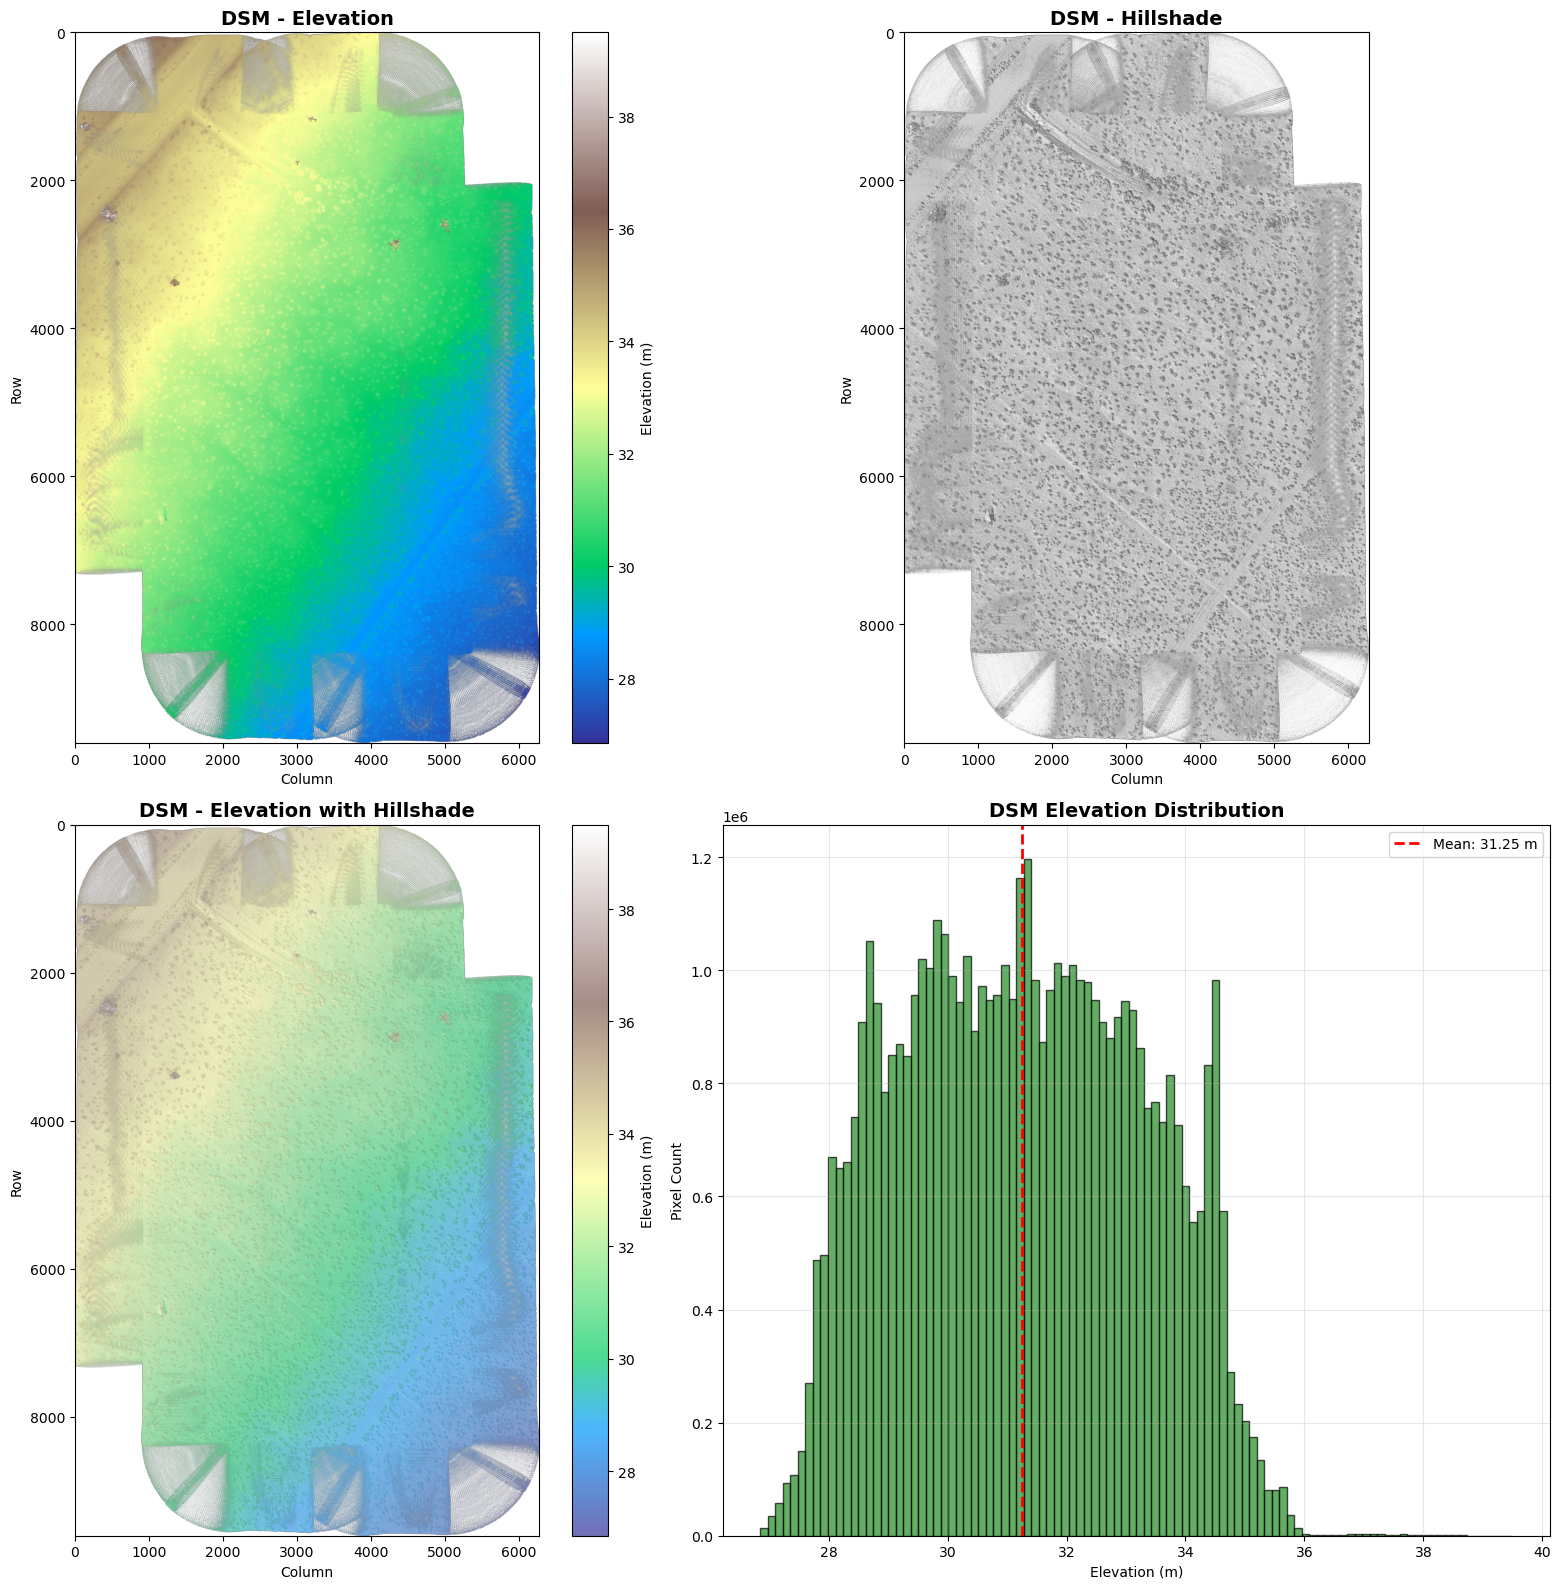

In [7]:
# Visualize DSM
if Path(dsm_path).exists():
    fig, axes = plt.subplots(2, 2, figsize=(18, 16))
    
    # 1. Standard elevation view
    im1 = axes[0, 0].imshow(dsm_valid, cmap='terrain', interpolation='bilinear')
    axes[0, 0].set_title('DSM - Elevation', fontsize=14, fontweight='bold')
    axes[0, 0].set_xlabel('Column')
    axes[0, 0].set_ylabel('Row')
    plt.colorbar(im1, ax=axes[0, 0], label='Elevation (m)', fraction=0.046, pad=0.04)
    
    # 2. Hillshade view
    ls = LightSource(azdeg=315, altdeg=45)
    hillshade = ls.hillshade(dsm_valid, vert_exag=2, dx=dsm_profile['transform'][0], dy=dsm_profile['transform'][4])
    axes[0, 1].imshow(hillshade, cmap='gray', interpolation='bilinear')
    axes[0, 1].set_title('DSM - Hillshade', fontsize=14, fontweight='bold')
    axes[0, 1].set_xlabel('Column')
    axes[0, 1].set_ylabel('Row')
    
    # 3. Elevation with hillshade overlay
    im3 = axes[1, 0].imshow(dsm_valid, cmap='terrain', alpha=0.7, interpolation='bilinear')
    axes[1, 0].imshow(hillshade, cmap='gray', alpha=0.3, interpolation='bilinear')
    axes[1, 0].set_title('DSM - Elevation with Hillshade', fontsize=14, fontweight='bold')
    axes[1, 0].set_xlabel('Column')
    axes[1, 0].set_ylabel('Row')
    plt.colorbar(im3, ax=axes[1, 0], label='Elevation (m)', fraction=0.046, pad=0.04)
    
    # 4. Elevation histogram
    dsm_flat = dsm_valid.compressed() if hasattr(dsm_valid, 'compressed') else dsm_valid.flatten()
    axes[1, 1].hist(dsm_flat, bins=100, color='forestgreen', edgecolor='black', alpha=0.7)
    axes[1, 1].set_title('DSM Elevation Distribution', fontsize=14, fontweight='bold')
    axes[1, 1].set_xlabel('Elevation (m)')
    axes[1, 1].set_ylabel('Pixel Count')
    axes[1, 1].axvline(dsm_valid.mean(), color='red', linestyle='--', linewidth=2, 
                       label=f'Mean: {dsm_valid.mean():.2f} m')
    axes[1, 1].legend()
    axes[1, 1].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()

## Compare Point Cloud vs DSM

Compare elevation statistics between the original LiDAR point cloud and the gridded DSM.

In [15]:
# Comparison
if Path(las_path).exists() and Path(dsm_path).exists():
    print("="*70)
    print("POINT CLOUD vs DSM COMPARISON")
    print("="*70)
    
    # Statistics comparison
    comparison = {
        'Metric': ['Min Elevation (m)', 'Max Elevation (m)', 'Mean Elevation (m)', 
                   'Std Dev (m)', 'Range (m)'],
        'Point Cloud': [f"{z.min():.3f}", f"{z.max():.3f}", f"{z.mean():.3f}", 
                        f"{z.std():.3f}", f"{z.max()-z.min():.3f}"],
        'DSM': [f"{dsm_valid.min():.3f}", f"{dsm_valid.max():.3f}", f"{dsm_valid.mean():.3f}", 
                f"{dsm_valid.std():.3f}", f"{dsm_valid.max()-dsm_valid.min():.3f}"]
    }
    
    print(f"{'Metric':<25} {'Point Cloud':<15} {'DSM':<15} {'Difference':<15}")
    print("-" * 70)
    
    pc_values = [z.min(), z.max(), z.mean(), z.std(), z.max()-z.min()]
    dsm_values = [dsm_valid.min(), dsm_valid.max(), dsm_valid.mean(), dsm_valid.std(), 
                  dsm_valid.max()-dsm_valid.min()]
    
    for i, metric in enumerate(comparison['Metric']):
        diff = dsm_values[i] - pc_values[i]
        print(f"{metric:<25} {pc_values[i]:<15.3f} {dsm_values[i]:<15.3f} {diff:<15.3f}")
    
    print("\n" + "="*70)
    print("DATA DENSITY")
    print("="*70)
    
    # Calculate point density
    las_area = (las.header.x_max - las.header.x_min) * (las.header.y_max - las.header.y_min)
    point_density = las.header.point_count / las_area
    
    # Calculate DSM pixel area
    pixel_area = abs(dsm_profile['transform'][0] * dsm_profile['transform'][4])
    
    print(f"Point Cloud Density: {point_density:.2f} points/m²")
    print(f"DSM Pixel Size: {dsm_profile['transform'][0]:.4f} m ({dsm_profile['transform'][0]*100:.2f} cm)")
    print(f"DSM Pixel Area: {pixel_area:.6f} m²")
    print(f"Total LAS Points: {las.header.point_count:,}")
    print(f"Total DSM Pixels: {dsm.size:,}")
    
    # Spatial overlap check
    print("\n" + "="*70)
    print("SPATIAL OVERLAP")
    print("="*70)
    
    overlap_x = min(las.header.x_max, dsm_bounds.right) - max(las.header.x_min, dsm_bounds.left)
    overlap_y = min(las.header.y_max, dsm_bounds.top) - max(las.header.y_min, dsm_bounds.bottom)
    
    if overlap_x > 0 and overlap_y > 0:
        print(f"✅ Spatial overlap: {overlap_x:.2f} m (X) × {overlap_y:.2f} m (Y)")
    else:
        print("⚠️ WARNING: No spatial overlap detected!")
    
    print("="*70)

POINT CLOUD vs DSM COMPARISON


Metric                    Point Cloud     DSM             Difference     
----------------------------------------------------------------------
Min Elevation (m)         26.837          26.851          0.014          
Max Elevation (m)         39.498          39.498          0.000          
Mean Elevation (m)        31.284          31.252          -0.032         
Std Dev (m)               1.869           1.997           0.128          
Range (m)                 12.660          12.647          -0.014         

DATA DENSITY
Point Cloud Density: 1283.13 points/m²
DSM Pixel Size: 0.0300 m (3.00 cm)
DSM Pixel Area: 0.000900 m²
Total LAS Points: 69,596,825
Total DSM Pixels: 60,280,980

SPATIAL OVERLAP
✅ Spatial overlap: 188.24 m (X) × 288.14 m (Y)


## Export Statistics Summary

In [18]:
from pathlib import Path

# ------------------------------------------------------------------
# Optional: Save summary to fixed output directory
# ------------------------------------------------------------------
if Path(las_path).exists() and Path(dsm_path).exists():

    output_dir = Path(
        "/home/nvidia/projects/fvc_structure/phase_1_image_processing/"
        "step_1_imagesAlignment/output"
    )
    output_dir.mkdir(parents=True, exist_ok=True)

    summary_file = output_dir / f"l2_{Path(las_path).stem}_vs_dsm_summary.txt"

    with open(summary_file, "w") as f:
        f.write("LiDAR POINT CLOUD vs DSM COMPARISON SUMMARY\n")
        f.write("=" * 70 + "\n\n")

        f.write(f"LAS File: {las_path}\n")
        f.write(f"DSM File: {dsm_path}\n\n")

        f.write("POINT CLOUD STATISTICS:\n")
        f.write(f"  Total Points: {las.header.point_count:,}\n")
        f.write(f"  Point Density: {point_density:.2f} points/m²\n")
        f.write(f"  Elevation Range: {z.min():.3f} to {z.max():.3f} m\n")
        f.write(f"  Mean Elevation: {z.mean():.3f} m\n\n")

        f.write("DSM STATISTICS:\n")
        f.write(f"  Dimensions: {dsm_profile['width']} x {dsm_profile['height']} pixels\n")
        f.write(f"  Resolution: {dsm_profile['transform'][0]:.4f} m/pixel\n")
        f.write(f"  Elevation Range: {dsm_valid.min():.3f} to {dsm_valid.max():.3f} m\n")
        f.write(f"  Mean Elevation: {dsm_valid.mean():.3f} m\n\n")

        f.write("DIFFERENCES:\n")
        f.write(
            f"  Mean Elevation Difference (DSM − LiDAR): "
            f"{dsm_valid.mean() - z.mean():.3f} m\n"
        )
        f.write(
            f"  Range Difference: "
            f"{(dsm_valid.max() - dsm_valid.min()) - (z.max() - z.min()):.3f} m\n"
        )

    print(f"\n📄 Summary saved to:\n  {summary_file}")



📄 Summary saved to:
  /home/nvidia/projects/fvc_structure/phase_1_image_processing/step_1_imagesAlignment/output/l2_cloud3358f88f2d9dc868_vs_dsm_summary.txt
